# California House Price Prediction: From Data to Model Evaluation

**Experiment 1 – Regression with Linear Regression**

Predicting the median house value of California districts from census data (1990).

**To run:** keep **housing.csv** in the same folder as this notebook (in Colab, upload it to the Files panel), then **Run All**.

In [1]:
# 1. Import the libraries
# We need pandas for tables, numpy for maths, matplotlib for charts and scikit-learn for the
# models and metrics.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
# 2. Load the housing CSV
# The CSV file (housing.csv) must be in the same folder as this notebook.
# pd.read_csv loads the file into a DataFrame called data, and the print confirms it loaded
# (20,640 rows, 10 columns).

data_path = "housing.csv"
data = pd.read_csv(data_path)

print("Loaded:", data_path)
print("Rows:", len(data), "| Columns:", len(data.columns))

Loaded: housing.csv
Rows: 20640 | Columns: 10


In [3]:
# 3. Explore The Dataset
# 3.1 View the table
# Shows the table so we can see what the data looks like. Each row is one district, not one
# house.

data

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY
...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND


In [4]:
# 3.2 First five districts
# head() shows the first 5 rows, so we can check the column names and the type of values.

data.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [5]:
# 3.3 Last five districts
# tail() shows the last 5 rows, to make sure the whole file loaded properly.

data.tail()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND
20639,-121.24,39.37,16.0,2785.0,616.0,1387.0,530.0,2.3886,89400.0,INLAND


In [6]:
# 3.4 Rows and columns
# shape gives (rows, columns). 20,640 rows and 9 features, so it meets the brief (500+ rows, 5+
# features).

data.shape

(20640, 10)

In [7]:
# 3.5 Column types and missing counts
# info() shows that total_bedrooms has missing values and ocean_proximity is text, so both need
# fixing before training.

data.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


In [8]:
# 3.6 Summary statistics
# describe() gives quick statistics. The max house value is exactly 500,001, which looks like a
# cap.

data.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [9]:
# 3.7 Count missing values
# isnull().sum() counts missing values per column: only total_bedrooms has some (207).

data.isnull().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

In [10]:
# 3.8 Check the text column
# value_counts() shows the 5 categories in ocean_proximity. ISLAND has only 5 districts.

data["ocean_proximity"].value_counts()

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

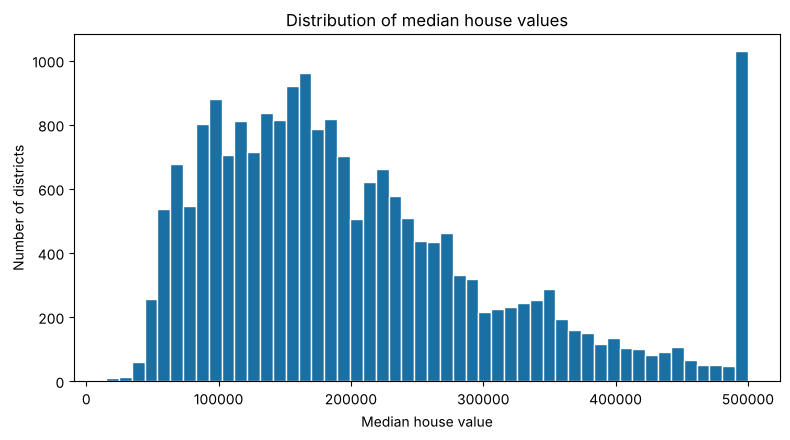

Districts at the $500,001 cap: 992


In [11]:
# 3.9 Distribution of house values
# The histogram shows most districts are cheaper, plus a tall bar at the $500,001 cap (992
# districts).

plt.figure(figsize=(8, 4.5))
plt.hist(data["median_house_value"], bins=50, color="#1A6FA3", edgecolor="white")
plt.xlabel("Median house value")
plt.ylabel("Number of districts")
plt.title("Distribution of median house values")
plt.ticklabel_format(style="plain", axis="x")
plt.tight_layout()
plt.show()

capped = (data["median_house_value"] >= 500000).sum()
print("Districts at the $500,001 cap:", capped)

In [12]:
# What I noticed:
# - 992 districts were stuck at $500,001, so their real value is unknown.
# - I removed them so the model doesn't learn wrong answers.

In [13]:
# 3.10 Remove the capped districts
# We remove the capped districts because their real value is unknown, which leaves 19,648 rows.

data = data[data["median_house_value"] < 500000].reset_index(drop=True)
print("Rows after removing capped districts:", len(data))

Rows after removing capped districts: 19648


In [14]:
# 3.11 Correlation with house value
# The correlation shows which columns move with house value. median_income is the strongest (about
# 0.65).

data.corr(numeric_only=True)["median_house_value"].sort_values(ascending=False)

median_house_value    1.000000
median_income         0.646719
total_rooms           0.144988
households            0.095634
total_bedrooms        0.075219
housing_median_age    0.065139
population            0.013592
longitude            -0.045733
latitude             -0.149257
Name: median_house_value, dtype: float64

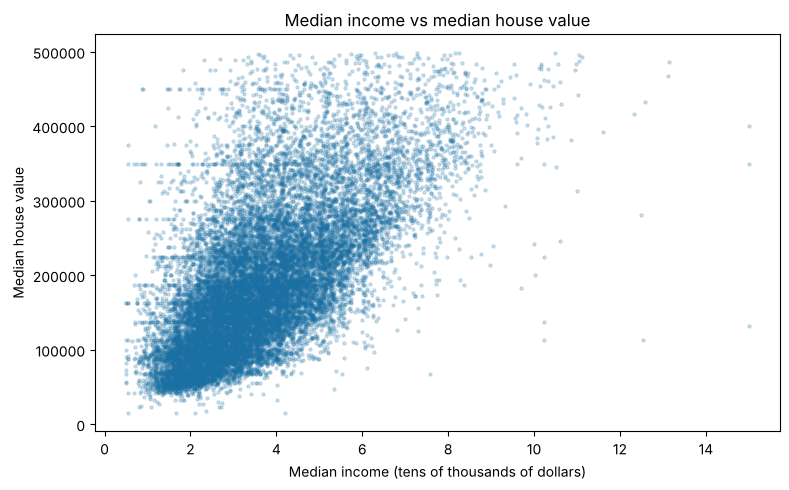

In [15]:
# 3.12 Income vs house value
# Each dot is a district. So the upward slope shows higher income usually means higher house value.

plt.figure(figsize=(8, 5))
plt.scatter(data["median_income"], data["median_house_value"], alpha=0.2, s=5, color="#1A6FA3")
plt.xlabel("Median income (tens of thousands of dollars)")
plt.ylabel("Median house value")
plt.title("Median income vs median house value")
plt.ticklabel_format(style="plain", axis="y")
plt.tight_layout()
plt.show()

In [16]:
# What I noticed:
# - median_income has the strongest link with house value (about 0.65).
# - The dots are spread out, so even a good model will make big errors.

In [17]:
# 4. Opting for Input and Targets
# 4.1 Create the input table X
# X holds the inputs. We drop the target, because giving the model the answer would be cheating.

X = data.drop(columns=["median_house_value"])

In [18]:
# 4.2 Check X
# A quick check that X has the right columns.

X.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,NEAR BAY


In [19]:
# 4.3 Create the target y
# y holds the target: the house value we want to predict.

y = data["median_house_value"]

In [20]:
# 4.4 Check y
# A quick check that y has the values we expect.

y.head()

0    452600.0
1    358500.0
2    352100.0
3    341300.0
4    342200.0
Name: median_house_value, dtype: float64

In [21]:
# 5. Data Preparation for Splitting
# 5.1 Encode the text column
# The model only understands numbers, so get_dummies turns each category into a 0/1 column.
# drop_first avoids repeating information.

X = pd.get_dummies(X, columns=["ocean_proximity"], drop_first=True, dtype=int)
X.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,0,0,1,0
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,0,0,1,0
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,0,0,1,0
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,0,0,1,0
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,0,0,1,0


In [22]:
# 5.2 Split into training and test sets
# 80% of the data trains the model and 20% is kept back to test it fairly. random_state=42 makes
# the split the same every time.

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [23]:
# 5.3 Look at training values
# Shows some training values. The row numbers are mixed because the split shuffles the data.

y_train.head()

12195     67000.0
13941    162500.0
8865     290800.0
4978     131700.0
1795     401000.0
Name: median_house_value, dtype: float64

In [24]:
# 5.4 Confirm the split sizes
# Checks that each set has the same number of inputs and targets (15,718 train, 3,930 test).

print("Training districts:", len(X_train))
print("Training values:", len(y_train))
print("Test districts:", len(X_test))
print("Test values:", len(y_test))

Training districts: 15718
Training values: 15718
Test districts: 3930
Test values: 3930


In [25]:
# 5.5 Fill missing values
# We fill the missing bedrooms with the median from the training data only, so the test data
# doesn't leak into training.

bedrooms_median = X_train["total_bedrooms"].median()
X_train = X_train.fillna({"total_bedrooms": bedrooms_median})
X_test = X_test.fillna({"total_bedrooms": bedrooms_median})

print("Training median used:", bedrooms_median)
print("Missing values left:", X_train.isnull().sum().sum() + X_test.isnull().sum().sum())

Training median used: 436.0
Missing values left: 0


In [26]:
# 5.6 Scale the features
# StandardScaler puts all columns on the same scale. It learns from the training data only and
# then applies the same scaling to the test data.

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [27]:
# ============================================================
# 6. BUILD AND TRAIN THE MODEL
# ============================================================
# 6.1 Create the model
# Creates the Linear Regression model. It hasn't learned anything yet.

model = LinearRegression()

In [28]:
# 6.2 Train the model
# fit() learns the best weight for each feature using the training data only.

model.fit(X_train_scaled, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](12,)","[-47881.85,-47114.38, 11301.68,..., 3020.79, -2446.09, 1513.49]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1.921e+05
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,12
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(12)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](12,)","[248.49,187.91,154.69,..., 29.85, 20.56, 17.34]"


In [29]:
# 6.3 What the model learned
# The coefficients show how much each feature pushes the predicted value up (positive) or down
# (negative).

coefficients = pd.DataFrame({"Feature": X.columns, "Coefficient": model.coef_})
display(coefficients.sort_values("Coefficient").round(0))

,Feature,Coefficient
0,longitude,-47882.0
1,latitude,-47114.0
5,population,-34911.0
8,ocean_proximity_INLAND,-18502.0
3,total_rooms,-11081.0
10,ocean_proximity_NEAR BAY,-2446.0
11,ocean_proximity_NEAR OCEAN,1513.0
9,ocean_proximity_ISLAND,3021.0
2,housing_median_age,11302.0
6,households,24368.0


In [30]:
# What I noticed:
# - median_income pushes the value up the most.
# - Inland districts and moving north or east push the value down.

In [31]:
# ============================================================
# 7. PREDICT VALUES FOR THE TEST DISTRICTS
# ============================================================
# 7.1 Make predictions
# predict() estimates a value for each test district. We never show the model the real test
# values.

house_price_prediction = model.predict(X_test_scaled)

In [32]:
# 7.2 First ten predictions
# The first 10 predictions. They are estimates, so they have decimals.

house_price_prediction[:10]

array([281517.6511893 , 272123.95122271, 268503.70056041, 202266.92966165,
       267457.33700918, 182098.61114458, 292107.91469511,  31823.99686508,
       170914.56797875, 292455.70218463])

In [33]:
# 7.3 Actual vs predicted table
# Puts real and predicted values side by side. Error = actual - predicted: positive means the
# model guessed too low.

comparison = pd.DataFrame({
    "Original row": y_test.index,
    "Actual value": y_test.to_numpy(),
    "Predicted value": house_price_prediction
})
comparison["Error"] = comparison["Actual value"] - comparison["Predicted value"]
comparison["Absolute error"] = comparison["Error"].abs()
display(comparison.head(10).round(2))

,Original row,Actual value,Predicted value,Error,Absolute error
0,8541,329800.0,281517.65,48282.35,48282.35
1,17084,294700.0,272123.95,22576.05,22576.05
2,16502,195700.0,268503.70,-72803.70,72803.70
3,3350,161500.0,202266.93,-40766.93,40766.93
4,15073,275000.0,267457.34,7542.66,7542.66
5,12393,137000.0,182098.61,-45098.61,45098.61
6,1535,266000.0,292107.91,-26107.91,26107.91
7,17720,81300.0,31824.00,49476.00,49476.00
8,7217,92800.0,170914.57,-78114.57,78114.57
9,1815,273700.0,292455.70,-18755.70,18755.70


In [34]:
# ============================================================
# 8. EVALUATE THE MODEL
# ============================================================
# 8.1 MSE
# MSE squares each error and averages them, so big mistakes count a lot. The units are dollars
# squared, which is why it's huge.

mse = mean_squared_error(y_test, house_price_prediction)
print(f"Test MSE: {mse:,.2f} squared dollars")

Test MSE: 3,712,114,220.49 squared dollars


In [35]:
# 8.2 RMSE
# RMSE is the square root of MSE, so it's back in dollars (about $60,900).

rmse = np.sqrt(mse)
print(f"Test RMSE: {rmse:,.2f} dollars")

Test RMSE: 60,927.12 dollars


In [36]:
# 8.3 MAE
# MAE is the average size of a mistake: about $45,300. This is the easiest number to explain.

mae = mean_absolute_error(y_test, house_price_prediction)
print(f"Test MAE: {mae:,.2f} dollars")

Test MAE: 45,345.48 dollars


In [37]:
# 8.4 R²
# R² of 0.613 means the model explains about 61% of the differences in house values.

r2 = r2_score(y_test, house_price_prediction)
print(f"Test R²: {r2:.4f}")

Test R²: 0.6128


In [38]:
# 8.5 Baseline
# The baseline always guesses the average value. Its MAE is about $78,600, so our model is much
# better.

baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train_scaled, y_train)
baseline_prediction = baseline.predict(X_test_scaled)

baseline_mae = mean_absolute_error(y_test, baseline_prediction)
print(f"Baseline MAE: {baseline_mae:,.2f} dollars")

Baseline MAE: 78,630.80 dollars


In [39]:
# 8.6 Training vs test
# Training and test scores are almost the same, so the model is not overfitting.

train_prediction = model.predict(X_train_scaled)
print(f"Training MAE: {mean_absolute_error(y_train, train_prediction):,.2f} | R²: {r2_score(y_train, train_prediction):.4f}")
print(f"Test MAE:     {mae:,.2f} | R²: {r2:.4f}")

Training MAE: 44,106.34 | R²: 0.6167
Test MAE:     45,345.48 | R²: 0.6128


In [40]:
# 8.7 Cross-validation
# Cross-validation tests the model on 5 different parts of the training data. The scores are
# similar, so the result is reliable.

cv_scores = cross_val_score(LinearRegression(), X_train_scaled, y_train, cv=5, scoring="r2")
print("R² for each fold:", cv_scores.round(4))
print(f"Average R²: {cv_scores.mean():.4f} (standard deviation {cv_scores.std():.4f})")

R² for each fold: [0.5894 0.6031 0.613  0.6339 0.6331]
Average R²: 0.6145 (standard deviation 0.0172)


In [41]:
# 8.8 Results in plain words
# Prints the main results in plain sentences, so they are easy to read.

print(f"We evaluated {len(y_test)} districts that were held back from training.")
print(f"The average absolute error was {mae:,.2f} dollars.")
print(f"RMSE was {rmse:,.2f} dollars; R² was {r2:.4f}.")

if mae < baseline_mae:
    print(f"Linear Regression has a lower test MAE than the baseline ({baseline_mae:,.2f} dollars).")
else:
    print("Linear Regression does not improve the test MAE over this baseline.")

print("The model still makes errors; inspect the individual predictions and plots.")

We evaluated 3930 districts that were held back from training.
The average absolute error was 45,345.48 dollars.
RMSE was 60,927.12 dollars; R² was 0.6128.
Linear Regression has a lower test MAE than the baseline (78,630.80 dollars).
The model still makes errors; inspect the individual predictions and plots.


In [42]:
# What I noticed:
# - The average error is about $45,300, much better than the baseline's $78,600.
# - R² is 0.613, and training and test scores are almost equal, so the model is not overfitting but is too simple.

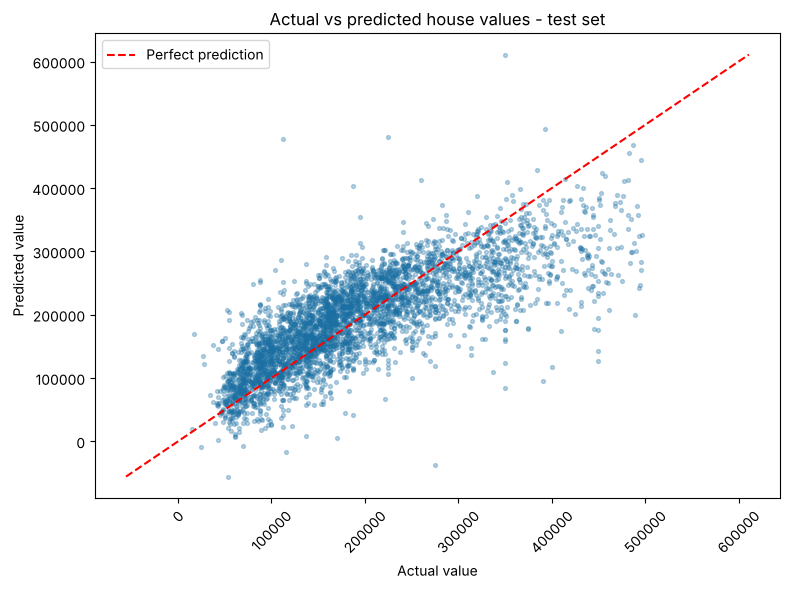

In [43]:
# 9. Prediction Error Visualization
# 9.1 Actual vs predicted plot
# Dots on the dashed line are perfect predictions. Dots below the line mean the model guessed too
# low.

plt.figure(figsize=(8, 6))
plt.scatter(y_test, house_price_prediction, alpha=0.3, s=8, color="#1A6FA3")

lowest_price = min(y_test.min(), house_price_prediction.min())
highest_price = max(y_test.max(), house_price_prediction.max())
plt.plot(
    [lowest_price, highest_price], [lowest_price, highest_price],
    "r--", label="Perfect prediction"
)

plt.xlabel("Actual value")
plt.ylabel("Predicted value")
plt.title("Actual vs predicted house values - test set")
plt.ticklabel_format(style="plain", axis="both")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

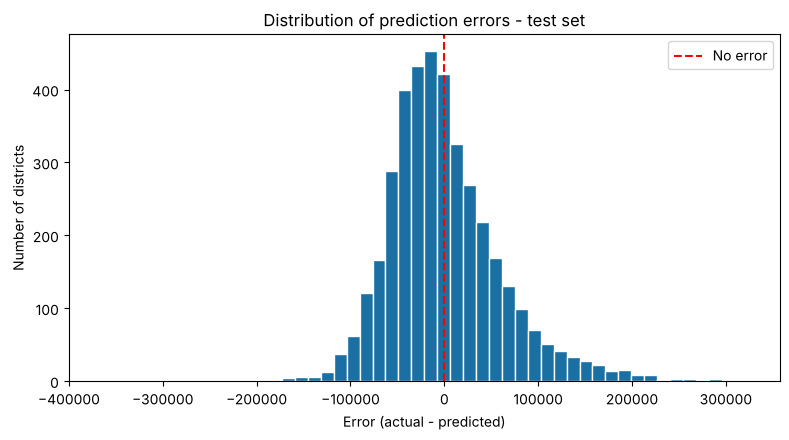

In [44]:
# 9.2 Error distribution
# Most errors are near 0, but there's a tail of big errors where the model guessed too low.

plt.figure(figsize=(8, 4.5))
plt.hist(comparison["Error"], bins=50, color="#1A6FA3", edgecolor="white")
plt.axvline(0, color="red", linestyle="--", label="No error")
plt.xlabel("Error (actual - predicted)")
plt.ylabel("Number of districts")
plt.title("Distribution of prediction errors - test set")
plt.ticklabel_format(style="plain", axis="x")
plt.legend()
plt.tight_layout()
plt.show()

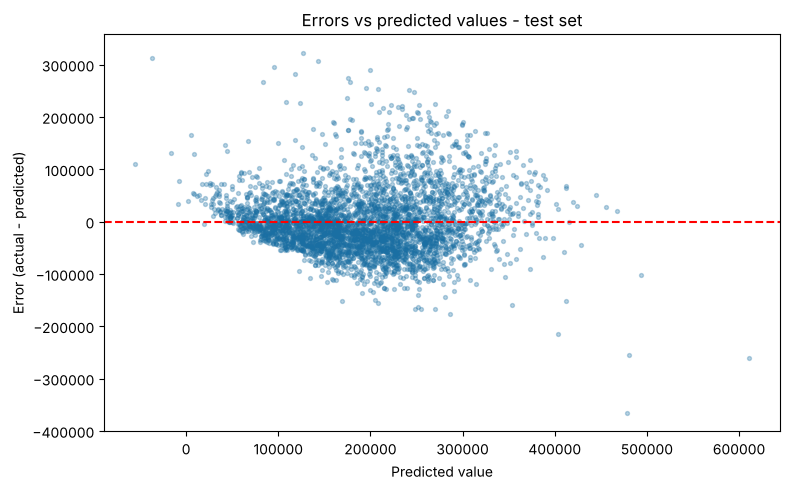

Predictions below $0: 5


In [45]:
# 9.3 Errors vs predicted values
# If the model fitted well, the errors would look random. Here the spread grows with price, so
# the model is less reliable for expensive areas.

plt.figure(figsize=(8, 5))
plt.scatter(house_price_prediction, comparison["Error"], alpha=0.3, s=8, color="#1A6FA3")
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted value")
plt.ylabel("Error (actual - predicted)")
plt.title("Errors vs predicted values - test set")
plt.ticklabel_format(style="plain", axis="both")
plt.tight_layout()
plt.show()

print("Predictions below $0:", (house_price_prediction < 0).sum())

In [46]:
# What I noticed:
# - Expensive districts are mostly predicted too low, and 5 predictions are below $0.
# - The errors get bigger for expensive districts.

In [47]:
# 10. Random Forest (Extension)
# 10.1 Random Forest
# A Random Forest uses many decision trees and averages them, so it can learn patterns that
# aren't straight lines.

forest_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
forest_model.fit(X_train_scaled, y_train)
forest_prediction = forest_model.predict(X_test_scaled)
forest_train_prediction = forest_model.predict(X_train_scaled)

print(f"Random Forest training R²: {r2_score(y_train, forest_train_prediction):.4f}")
print(f"Random Forest test MAE: {mean_absolute_error(y_test, forest_prediction):,.2f} | R²: {r2_score(y_test, forest_prediction):.4f}")

Random Forest training R²: 0.9713
Random Forest test MAE: 30,190.81 | R²: 0.7865


In [48]:
# 10.2 Compare the models
# Puts all the models' scores in one table so we can compare them.

all_predictions = {
    "Baseline (average)": baseline_prediction,
    "Linear Regression": house_price_prediction,
    "Random Forest": forest_prediction,
}

results = pd.DataFrame({
    "MAE": [mean_absolute_error(y_test, p) for p in all_predictions.values()],
    "RMSE": [np.sqrt(mean_squared_error(y_test, p)) for p in all_predictions.values()],
    "R²": [r2_score(y_test, p) for p in all_predictions.values()],
}, index=all_predictions.keys())
display(results.round(2))

,MAE,RMSE,R²
Baseline (average),78630.80,97914.64,-0.00
Linear Regression,45345.48,60927.12,0.61
Random Forest,30190.81,45242.24,0.79


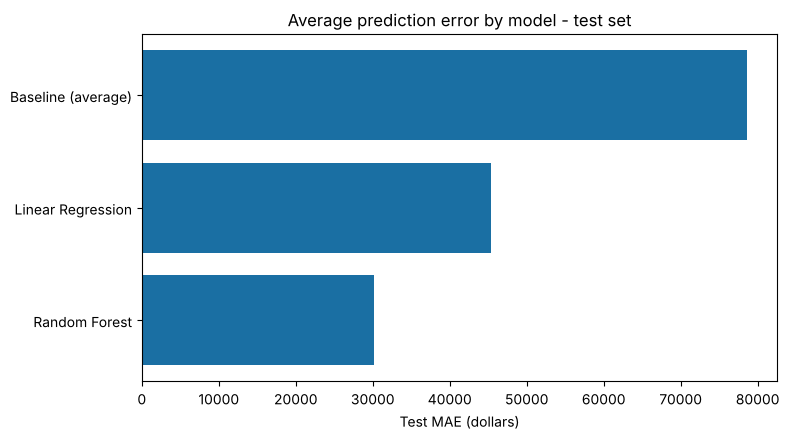

In [49]:
# 10.3 Plot the comparison
# A bar chart of each model's average error. Shorter bars are better.

plt.figure(figsize=(8, 4.5))
plt.barh(results.index, results["MAE"], color="#1A6FA3")
plt.xlabel("Test MAE (dollars)")
plt.title("Average prediction error by model - test set")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [50]:
# What I noticed:
# - Random Forest has the lowest error (about $30,200, R² 0.787).
# - But it overfits (training R² 0.971 vs test 0.787), and it is harder to explain than Linear Regression.

In this experiment I predicted the median house value of California districts from 1990 census data. The dataset has 20,640 districts and 9 features, including income, house age, number of rooms, population and location. Before training, I went through the data and found a few problems. House values were capped at $500,001, so 992 districts didn't show their real value. I removed them, which left 19,648 rows. The total_bedrooms column had 207 missing values, and ocean_proximity was text, which the model couldn't use directly.

To prepare the data, I turned ocean_proximity into 0/1 columns with get_dummies and split the data 80/20 into training and test sets. I filled the missing bedroom values with the training-set median and scaled all the features with StandardScaler. Both the median and the scaling were learned from the training data only, so the model never saw the test data before evaluation.

Linear Regression had a mean absolute error (MAE) of about $45,300, meaning its predictions were off by roughly $45,000 on average. The RMSE was about $60,900 and the MSE about 3.7 billion. The MSE looks huge because it's in squared dollars, which is why MAE and RMSE are easier to read. The R² was 0.613, so the model explains about 61% of the variation in house values. A baseline that always guesses the average had an MAE of about $78,600, so the model cut the error by around 42%. Training and test scores were very close, and cross-validation gave a similar result, so the model didn't overfit.

Linear Regression trains in seconds and is easy to explain: each coefficient shows how much a feature pushes the value up or down. Median income, for example, has a large positive effect. The problem is that a straight line is too simple for this data. The charts showed the model underestimating expensive districts, and it predicted a few negative values, which is impossible for a house. Its errors also grew as district values rose, so the linear assumption doesn't fully hold.

As an extension, I tried Random Forest on the same split. To my surprise it did much better, with an MAE of about $30,200 and an R² of 0.787, because it can pick up patterns that aren't straight lines. It did overfit, though (training R² of 0.971 against 0.787 on the test set), and it's harder to explain than Linear Regression.

Linear Regression is a good starting point that clearly beats guessing, but a more flexible model fits this data better. Next time I would limit how deep the Random Forest's trees can grow to reduce overfitting, and try adding features such as distance to the coast.

### References
- Nugent, C. (n.d.) *California Housing Prices* [dataset]. Kaggle. Available at: https://www.kaggle.com/datasets/camnugent/california-housing-prices
- Géron, A. (2019) *Hands-On Machine Learning with Scikit-Learn, Keras and TensorFlow*. 2nd edn. Sebastopol, CA: O'Reilly Media.
- Pace, R.K. and Barry, R. (1997) 'Sparse spatial autoregressions', *Statistics & Probability Letters*, 33(3), pp. 291–297.
- Pedregosa, F. *et al.* (2011) 'Scikit-learn: Machine learning in Python', *Journal of Machine Learning Research*, 12, pp. 2825–2830.